# Treino das MobileNets no dataset da universidade (UFSM)

In [11]:
from google.colab import drive
drive.mount('/content/drive')

PROJECT  = '/content/drive/MyDrive/Mestrado/mobilenet_cenas'   # código (src/, scripts/, configs/)
UFSM_DIR = '/content/drive/MyDrive/Mestrado/ufsm'              # fotos, vídeos e .py
UFSM_DATA = f'{UFSM_DIR}/data'                                   # saída processada
RESULTS  = f'{UFSM_DIR}/results'

import os, sys, glob, shutil
os.chdir(PROJECT)
!pip install -q timm>=1.0
!nvidia-smi -L

# se houver .py na pasta ufsm, eles substituem os do projeto
for f in glob.glob(f'{UFSM_DIR}/**/*.py', recursive=True):
    shutil.copy2(f, 'src' if os.path.basename(f) in os.listdir('src') else 'scripts')
MODELS = ['mobilenetv1', 'mobilenetv2', 'mobilenetv3_small', 'mobilenetv3_large']
SEEDS = [0, 1, 2]
print('imagens originais:', len(glob.glob(f'{UFSM_DIR}/**/*.jpg', recursive=True)),
      '| vídeos:', len(glob.glob(f'{UFSM_DIR}/**/*.mp4', recursive=True)))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GPU 0: Tesla T4 (UUID: GPU-cdb0b7f7-8491-f480-c22c-867ad5810293)
imagens originais: 730 | vídeos: 3


## 1. Preparar fotos e frames

Corrige a rotação, reduz para 1024 px e extrai 1 frame por segundo dos vídeos. Saída em `ufsm/data/images`. Pode rodar de novo: pula o que já existe.

In [2]:
dirs = sorted({os.path.dirname(f) for f in glob.glob(f'{UFSM_DIR}/**/*.*', recursive=True)
               if f.lower().endswith(('.jpg', '.jpeg', '.png', '.mp4', '.mov')) and '/data/' not in f})
for d in dirs:
    !python scripts/prepare_ufsm.py resize --src "{d}" --root "{UFSM_DATA}"
    !python scripts/prepare_ufsm.py frames --src "{d}" --root "{UFSM_DATA}" --fps 1
print(len([f for f in os.listdir(f'{UFSM_DATA}/images') if f.endswith('.jpg')]), 'imagens ainda sem classe em data/images')

357 fotos em /content/drive/MyDrive/Mestrado/ufsm/data/images
20260910_133256.mp4: 6 frames (30 fps de origem, 1 a cada 30)
20260910_133534.mp4: 6 frames (30 fps de origem, 1 a cada 30)
20260910_133940.mp4: 4 frames (30 fps de origem, 1 a cada 30)
16 frames de 3 vídeos em /content/drive/MyDrive/Mestrado/ufsm/data/images
373 imagens ainda sem classe em data/images


## 1b. Objetos e proximidade (sem rótulos, sem treino)

Dois modelos já treinados: SegFormer no ADE20K (parede, porta, cadeira, pessoa, chão, escada...) e Depth Anything (profundidade relativa). Para cada foto sai um painel: foto, objetos, mapa de proximidade (quente = perto) e os obstáculos que estão no terço mais próximo. Saída em `ufsm/results/objetos`. Na primeira vez baixa ~200 MB de modelos.

config.json: 100% 6.88k/6.88k [00:00<00:00, 20.0MB/s]

model.safetensors: downloading bytes:   0% 0.00/15.0M [00:00<?, ?B/s]
model.safetensors: downloading bytes:  70% 10.5M/15.0M [00:00<00:00, 11.9MB/s]
model.safetensors: downloading bytes: 100% 14.2M/14.2M [00:01<00:00, 13.6MB/s, 1.38MB/s  ]
model.safetensors: reconstructing file: 100% 15.0M/15.0M [00:01<00:00, 14.4MB/s, 1.46MB/s  ]
Loading weights: 100% 208/208 [00:00<00:00, 4657.25it/s]
preprocessor_config.json: 100% 271/271 [00:00<00:00, 1.06MB/s]
config.json: 100% 950/950 [00:00<00:00, 4.24MB/s]

model.safetensors: downloading bytes:  74% 73.8M/99.2M [00:00<00:00, 137MB/s, 4.94MB/s  ]
model.safetensors: downloading bytes: 100% 94.1M/94.1M [00:01<00:00, 78.6MB/s, 9.01MB/s  ]
model.safetensors: reconstructing file: 100% 99.2M/99.2M [00:01<00:00, 82.7MB/s, 9.65MB/s  ]
Loading weights: 100% 287/287 [00:00<00:00, 4350.80it/s]
preprocessor_config.json: 100% 775/775 [00:00<00:00, 4.28MB/s]
20260910_133117.jpg -> chão (16%), parede (14%)

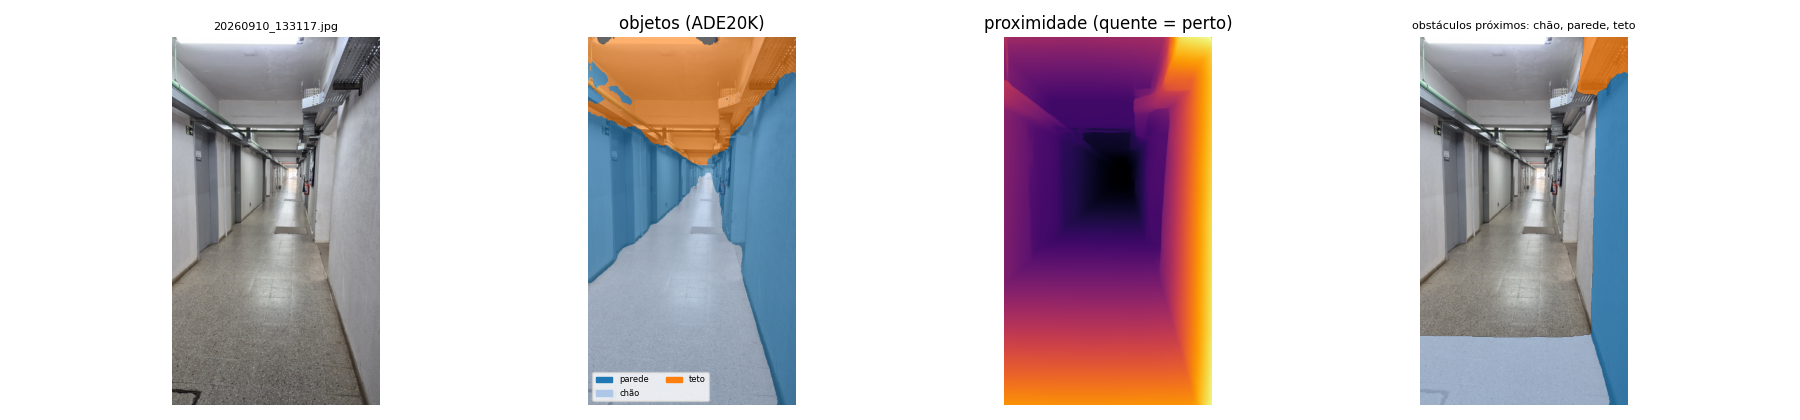

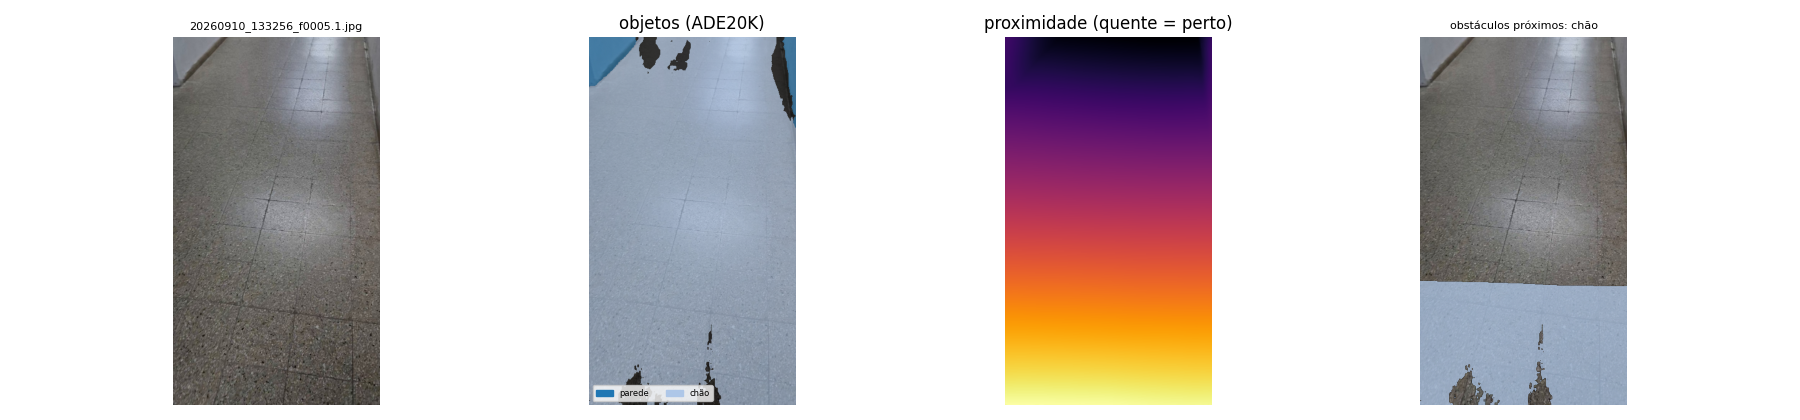

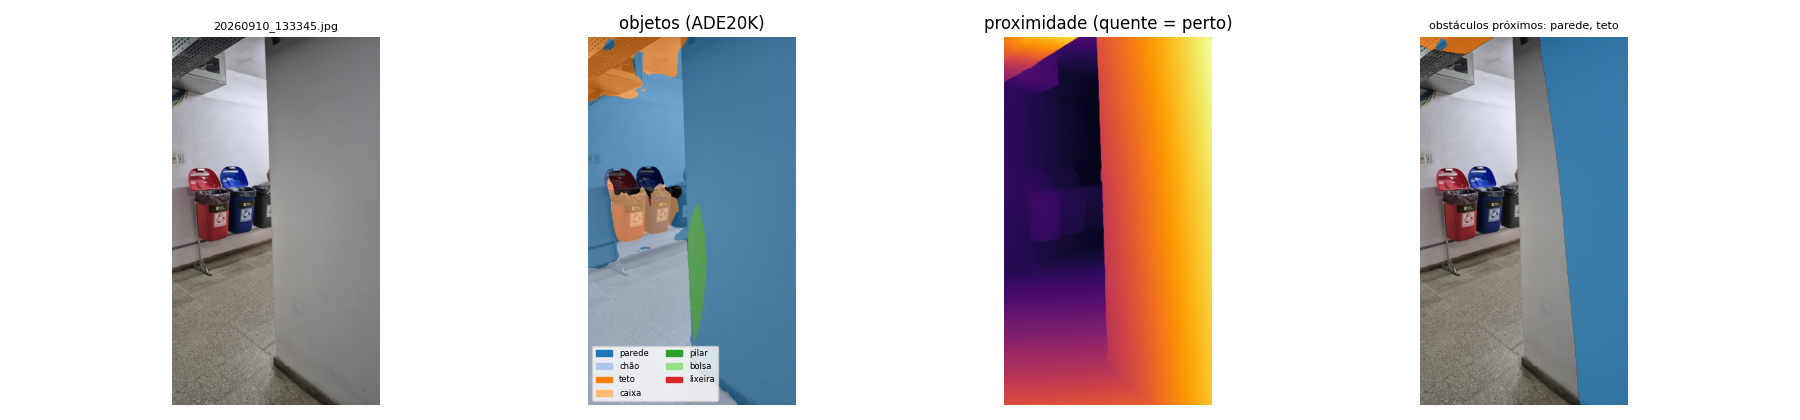

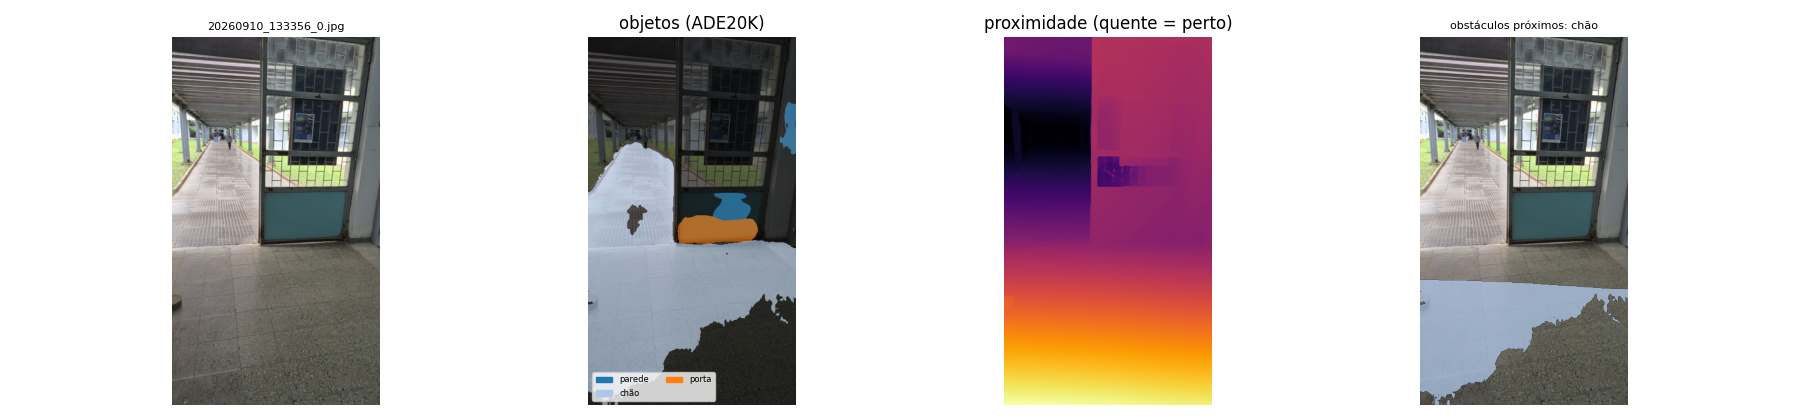

In [13]:
!pip install -q transformers
!python -m src.objetos_proximos --images "{UFSM_DATA}/images" --out "{RESULTS}/objetos" --max_images 24

from IPython.display import Image as _Img, display
import glob
for f in sorted(glob.glob(f'{RESULTS}/objetos/*_objetos.png'))[:4]:
    display(_Img(f, width=1100))

## 1c. Pré-rotulagem automática (opcional)

In [14]:
ckpt = 'results/mit67/rgb/mobilenetv1/seed0/best.pt'
if os.path.exists(ckpt):
    !python scripts/prelabel_ufsm.py --root "{UFSM_DATA}" --model mobilenetv1 --checkpoint {ckpt} --classes data/mit67/classes.json
else:
    print('sem checkpoint do MIT67; rotule à mão')

{'corredor': 67, 'hall': 77, 'outros': 228, 'sala': 1} | detalhe em prelabel.csv


## 2. Rotular

No Drive, dentro de `ufsm/data/images`, crie uma pasta por classe (ex.: `corredor`, `porta`, `hall`, `sala`, `externa`) e mova cada imagem para a pasta certa. Imagens deixadas soltas em `images/` ficam de fora. A célula abaixo confere.

In [15]:
classes = sorted(d for d in os.listdir(f'{UFSM_DATA}/images') if os.path.isdir(f'{UFSM_DATA}/images/{d}'))
assert classes, 'Nenhuma subpasta de classe em ufsm/data/images: rotule antes de continuar.'
for c in classes:
    print(f'{c:15s}', len(os.listdir(f'{UFSM_DATA}/images/{c}')))

corredor        67
hall            77
outros          228
sala            1


## 3. Gerar os CSVs (divisão por grupo)

Fotos do mesmo minuto e frames do mesmo vídeo ficam na mesma partição, para não vazar quase-duplicatas do treino para o teste.

In [16]:
!python scripts/prepare_ufsm.py csv --root "{UFSM_DATA}" --split
!rm -rf /content/data/ufsm && mkdir -p /content/data/ufsm
!cp -r "{UFSM_DATA}/images" "{UFSM_DATA}"/*.csv "{UFSM_DATA}"/*.json /content/data/ufsm/

/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_split.py:1023: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=5.
  warnings.warn(
treino 239 | val 20 | teste 114 (16 grupos)
col_0     teste  treino  val
scene                       
corredor     21      43    3
hall         33      36    8
outros       59     160    9
sala          1       0    0
scene
outros      228
hall         77
corredor     67
sala          1


## 4. Treinar

4 modelos × 3 sementes com `configs/ufsm.yaml` (60 épocas, batch 32). Cada execução salva `metrics.json` e é pulada se já existir; dá para interromper e retomar. Resultados em `ufsm/results`.

In [18]:
for m in MODELS:
    for s in SEEDS:
        if os.path.exists(f'{RESULTS}/ufsm/rgb/{m}/seed{s}/metrics.json'):
            print('ok  ', m, s); continue
        print('=== ', m, 'seed', s, flush=True)
        !python -m src.train --config configs/ufsm.yaml --model {m} --seed {s} --data_root /content/data/ufsm --out_dir "{RESULTS}"

===  mobilenetv1 seed 0
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/usr/local/lib/pyt

In [19]:
!python -m src.aggregate --results "{RESULTS}" --out "{RESULTS}/summary_ufsm.csv"
!python -m src.benchmark --num_classes {len(classes)} --out "{RESULTS}/benchmark_ufsm.csv"

dataset variant             model  params_M  n_seeds     test_acc test_mean_class_acc test_f1_macro
   ufsm     rgb       mobilenetv1  3.211076        3  57.6 ± 5.29       51.23 ± 16.92  46.18 ± 7.91
   ufsm     rgb       mobilenetv2  2.228996        3 55.85 ± 6.64        41.73 ± 5.21  41.25 ± 4.39
   ufsm     rgb mobilenetv3_large  4.207156        3 60.82 ± 1.34        47.08 ± 1.16  45.34 ± 0.44
   ufsm     rgb mobilenetv3_small  1.521956        3  61.7 ± 4.83        46.08 ± 3.16  44.26 ± 4.07
{'model': 'mobilenetv1', 'fusion': 'none', 'params_M': 3.211076, 'MACs_M': 567.720448, 'cpu_ms': 31.05099499998687, 'gpu_ms': 3.1132399999478366, 'gpu': 'Tesla T4', 'cpu': 'x86_64'}
{'model': 'mobilenetv2', 'fusion': 'none', 'params_M': 2.228996, 'MACs_M': 299.499392, 'cpu_ms': 36.993523000091955, 'gpu_ms': 5.553232999773172, 'gpu': 'Tesla T4', 'cpu': 'x86_64'}
{'model': 'mobilenetv3_small', 'fusion': 'none', 'params_M': 1.521956, 'MACs_M': 55.490496, 'cpu_ms': 10.316258999864658, 'gpu_ms': 5.48

## 5. Opcional: matriz de confusão do melhor modelo

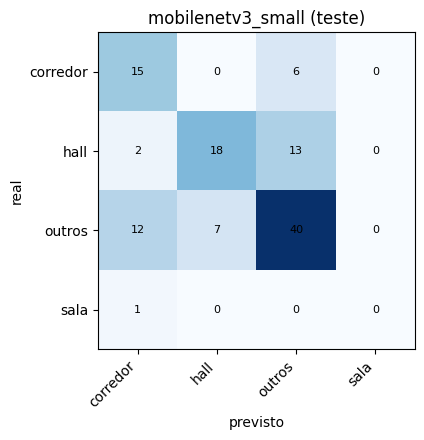

,model,params_M,test_acc_mean,test_acc_std,test_mean_class_acc_mean,test_f1_macro_mean
0,mobilenetv1,3.2111,0.5760,0.0529,0.5123,0.4618
1,mobilenetv2,2.2290,0.5585,0.0664,0.4173,0.4125
2,mobilenetv3_large,4.2072,0.6082,0.0134,0.4708,0.4534
3,mobilenetv3_small,1.5220,0.6170,0.0483,0.4608,0.4426


In [20]:
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt
summ = pd.read_csv(f'{RESULTS}/summary_ufsm.csv')
best = summ.sort_values('test_acc_mean', ascending=False).iloc[0]['model']
m = json.load(open(f'{RESULTS}/ufsm/rgb/{best}/seed0/metrics.json'))
cm = np.array(m['test']['confusion_matrix'])
fig, ax = plt.subplots(figsize=(5, 4.5))
ax.imshow(cm, cmap='Blues'); ax.set_xticks(range(len(classes))); ax.set_yticks(range(len(classes)))
ax.set_xticklabels(classes, rotation=45, ha='right'); ax.set_yticklabels(classes)
for i in range(len(classes)):
    for j in range(len(classes)):
        ax.text(j, i, cm[i, j], ha='center', va='center', fontsize=8)
ax.set_xlabel('previsto'); ax.set_ylabel('real'); ax.set_title(f'{best} (teste)')
plt.tight_layout(); plt.savefig(f'{RESULTS}/confusao_{best}.png', dpi=150); plt.show()
summ[['model', 'params_M', 'test_acc_mean', 'test_acc_std', 'test_mean_class_acc_mean', 'test_f1_macro_mean']].round(4)

## 6. Opcional: Grad-CAM e linear probe com os checkpoints do MIT67

Só funciona se os treinos do MIT67 estiverem em `mobilenet_cenas/results/mit67`.

In [21]:
for m in MODELS:
    ckpt = f'results/mit67/rgb/{m}/seed0/best.pt'
    if not os.path.exists(ckpt): print('sem checkpoint MIT67 para', m); continue
    !python -m src.gradcam --images "{UFSM_DATA}/images" --model {m} --checkpoint {ckpt} --classes data/mit67/classes.json --out "{RESULTS}/gradcam/{m}" --max_images 48
    !python -m src.linear_probe --root /content/data/ufsm --csv test.csv --model {m} --checkpoint {ckpt} --num_classes_ckpt 67 --out "{RESULTS}/probe_{m}.json"

salvo /content/drive/MyDrive/Mestrado/ufsm/results/gradcam/mobilenetv1/gradcam_mobilenetv1_01.png
salvo /content/drive/MyDrive/Mestrado/ufsm/results/gradcam/mobilenetv1/gradcam_mobilenetv1_02.png
salvo /content/drive/MyDrive/Mestrado/ufsm/results/gradcam/mobilenetv1/gradcam_mobilenetv1_03.png
/usr/bin/python3: No module named src.linear_probe
salvo /content/drive/MyDrive/Mestrado/ufsm/results/gradcam/mobilenetv2/gradcam_mobilenetv2_01.png
salvo /content/drive/MyDrive/Mestrado/ufsm/results/gradcam/mobilenetv2/gradcam_mobilenetv2_02.png
salvo /content/drive/MyDrive/Mestrado/ufsm/results/gradcam/mobilenetv2/gradcam_mobilenetv2_03.png
/usr/bin/python3: No module named src.linear_probe
salvo /content/drive/MyDrive/Mestrado/ufsm/results/gradcam/mobilenetv3_small/gradcam_mobilenetv3_small_01.png
salvo /content/drive/MyDrive/Mestrado/ufsm/results/gradcam/mobilenetv3_small/gradcam_mobilenetv3_small_02.png
salvo /content/drive/MyDrive/Mestrado/ufsm/results/gradcam/mobilenetv3_small/gradcam_mobil